In [1]:
import optuna
import joblib
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt 
from sklearn.metrics import f1_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import  cross_val_score

In [2]:
data = joblib.load("../processed_data.joblib")

[I 2026-07-25 08:15:15,179] A new study created in memory with name: no-name-dc78da84-e0ba-4e3f-8338-a2debc60ad1c
[I 2026-07-25 08:16:35,392] Trial 0 finished with value: 0.5283761434046074 and parameters: {'max_depth': 16, 'n_estimators': 200, 'max_features': 'log2', 'min_samples_split': 4, 'min_samples_leaf': 11}. Best is trial 0 with value: 0.5283761434046074.
[I 2026-07-25 08:16:49,994] Trial 4 finished with value: 0.5263991189083644 and parameters: {'max_depth': 9, 'n_estimators': 350, 'max_features': 'sqrt', 'min_samples_split': 18, 'min_samples_leaf': 13}. Best is trial 0 with value: 0.5283761434046074.
[I 2026-07-25 08:17:01,005] Trial 3 finished with value: 0.528658828916584 and parameters: {'max_depth': 19, 'n_estimators': 250, 'max_features': 'log2', 'min_samples_split': 13, 'min_samples_leaf': 9}. Best is trial 3 with value: 0.528658828916584.
[I 2026-07-25 08:17:30,802] Trial 10 finished with value: 0.5265756520638366 and parameters: {'max_depth': 10, 'n_estimators': 100, 

Optimal Hyperparameters: {'max_depth': 7, 'n_estimators': 500, 'max_features': None, 'min_samples_split': 16, 'min_samples_leaf': 5}
Highest Achieved Score: 0.5334


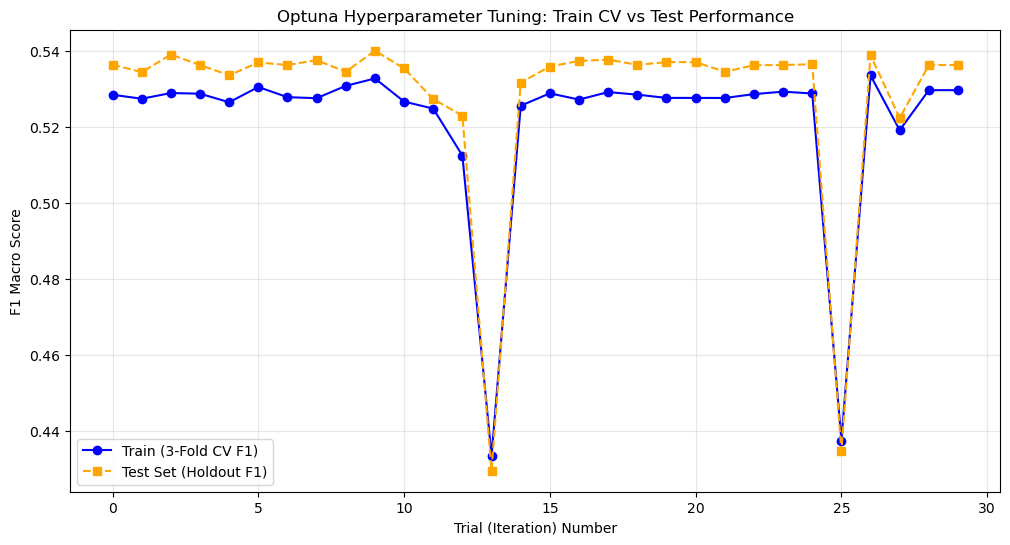

In [4]:
#! i didnt know how to store the scores whether on train and test , and how to predict also !!! so this is from ai help .
def objective(trial):
    # Unpack your data
    X_train, y_train = data['x_train'], data['y_train']
    X_test, y_test = data['x_test'], data['y_test']
    
    # 1. Define hyperparameter search space
    max_depth = trial.suggest_int('max_depth', 3, 20)
    n_estimators = trial.suggest_int('n_estimators', 50, 500, step=50)
    max_features = trial.suggest_categorical('max_features', ['sqrt', 'log2', None])
    min_samples_split = trial.suggest_int('min_samples_split', 2, 20)
    min_samples_leaf = trial.suggest_int('min_samples_leaf', 1, 20)

    clf = RandomForestClassifier(
        max_depth=max_depth,
        n_estimators=n_estimators,
        max_features=max_features,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,
        random_state=42
    )
    
    # 2. Strategy: Optuna optimizes based on Train-CV performance
    train_cv_score = cross_val_score(clf, X_train, y_train, cv=3, scoring='f1_macro').mean()
    
    # 3. Evaluation: Train a temporary model on ALL training data to check true test performance
    # This does not affect Optuna's decision-making logic but tracks the metric for your graph
    clf_temp = RandomForestClassifier(
        max_depth=max_depth, n_estimators=n_estimators, max_features=max_features,
        min_samples_split=min_samples_split, min_samples_leaf=min_samples_leaf, random_state=42
    )
    clf_temp.fit(X_train, y_train)
    test_preds = clf_temp.predict(X_test)
    test_score = f1_score(y_test, test_preds, average='macro')
    
    # 4. Save both scores safely inside Optuna's thread-safe tracking system
    trial.set_user_attr('train_cv_f1', train_cv_score)
    trial.set_user_attr('test_f1', test_score)
    
    return train_cv_score # Optuna optimizes this return value

if __name__ == '__main__':
    study = optuna.create_study(direction='maximize')
    study.optimize(objective, n_trials=30, n_jobs=-1)
    
    print(f"Optimal Hyperparameters: {study.best_params}")
    print(f"Highest Achieved Score: {study.best_value:.4f}")

    # ==================== GRAPHING TRAIN CV VS TEST ====================
    
    # Convert study trials into a DataFrame and sort chronologically
    df = study.trials_dataframe()
    df = df.sort_values(by='number')
    
    # Optuna automatically adds a 'user_attrs_' prefix to custom keys
    plt.figure(figsize=(12, 6))
    plt.plot(df['number'], df['user_attrs_train_cv_f1'], marker='o', label='Train (3-Fold CV F1)', color='blue')
    plt.plot(df['number'], df['user_attrs_test_f1'], marker='s', label='Test Set (Holdout F1)', color='orange', linestyle='--')
    
    plt.xlabel('Trial (Iteration) Number')
    plt.ylabel('F1 Macro Score')
    plt.title('Optuna Hyperparameter Tuning: Train CV vs Test Performance')
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()


***The score appears low because you are using f1_macro instead of raw accuracy.***

***The Class Imbalance Effect: Macro F1 calculates the F1-score for each class independently and averages them equally, regardless of how many samples each class has. If your dataset is imbalanced (e.g., 90% Class A and 10% Class B) and your model struggles to predict the minority class, your Macro F1 score will plummet heavily even if your accuracy is over 90%.***

***The Task Complexity: A baseline Macro F1 around 0.53 often suggests that the features currently provided do not have enough strong, linear, or non-linear predictive power to easily separate the target classes.***

***It is highly unusual for a test score to beat a training score, but looking closely at the previous code layout, there are two perfectly logical explanations for this:***

***More Training Data (The Main Reason): In your cross_val_score(cv=3), the model is trained on only 66.6% of your training data per fold. However, for the test evaluation step, your code trains clf_temp on 100% of your training data. Random Forests improve noticeably when given more samples, allowing the test-evaluated model to build better, deeper decision paths.***

***Data Distribution Luck: The test set may randomly contain slightly "cleaner" or easier-to-classify examples than the training set.***